# FULFILLMENT PULSE — 01 | Data Ingestion & Quality Audit

**Business question:** What operational factors are associated with longer food-delivery times, and can delivery duration be estimated from information available around order placement?

**Dataset:** Food Delivery dataset mirrored on Hugging Face (`aneesarom/Food-Delivery`). The dataset has 45,584 records across train/test parquet files and includes order, courier, weather, traffic, vehicle, location and delivery-time fields. The dataset is associated with the publicly shared Zomato Delivery Operations dataset on Kaggle. We will cite the Kaggle listing and the Hugging Face mirror in the final README.

**Important provenance note:** This is a public, third-party dataset attributed to Zomato delivery operations. We have not independently verified that it is an official Zomato production-data release. Do not describe it as proprietary or officially released by Zomato.

**This notebook's goal:** Load the untouched public data, inspect its structure, quantify data-quality issues and establish a reproducible baseline before cleaning or modelling.


## 1. Install and import libraries

In [1]:
!pip -q install datasets pandas numpy matplotlib seaborn scikit-learn

In [2]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42


## 2. Load the public dataset

The Hugging Face mirror exposes a train and test split. For descriptive analysis we combine both splits. We will create our own reproducible modelling split later, after cleaning and deciding which fields are safe to use.

In [3]:
dataset = load_dataset('aneesarom/Food-Delivery')

print(dataset)

raw_df = pd.concat(
    [dataset[split].to_pandas() for split in dataset.keys()],
    ignore_index=True
)

df = raw_df.copy()

print(f'Combined shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head(10))

README.md:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.76MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  447kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/36467 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9117 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
        num_rows: 36467
    })
    test: Dataset({
        features: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
        num_rows: 9117
    })
})
Combined shape: 45,584 rows × 20 colu

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0x6bbb,INDORES02DEL01,23.0,4.5,22.651847,75.881991,22.721847,75.951991,18-03-2022,22:10,22:25,Stormy,Low,1,Buffet,motorcycle,1.0,No,Metropolitian,17
1,0x190a,MYSRES20DEL01,39.0,4.3,12.337978,76.616792,12.377978,76.656792,17-03-2022,15:10,15:20,Cloudy,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,33
2,0x120c,MYSRES07DEL02,37.0,4.8,12.325461,76.632278,12.375461,76.682278,03-03-2022,23:55,24:10:00,Windy,Low,2,Meal,scooter,0.0,No,None,20
3,0x6016,SURRES12DEL03,30.0,4.8,21.183434,72.814492,21.213434,72.844492,05-03-2022,17:35,17:40,Sandstorms,Medium,0,Snack,motorcycle,0.0,No,Metropolitian,27
4,0x9ca0,VADRES13DEL02,29.0,4.6,22.310237,73.158921,22.360237,73.208921,11-03-2022,21:30,21:45,Cloudy,Jam,2,Buffet,scooter,0.0,No,Metropolitian,26
5,0x5066,PUNERES01DEL01,29.0,4.0,18.569156,73.774723,18.579156,73.784723,11-03-2022,09:20,09:30,Stormy,Low,0,Meal,motorcycle,1.0,No,Urban,25
6,0x3e6c,COIMBRES17DEL03,33.0,4.3,11.026117,76.944652,11.116117,77.034652,16-03-2022,21:40,21:45,Cloudy,Jam,2,Snack,electric_scooter,2.0,No,Metropolitian,46
7,0x477f,MYSRES18DEL02,32.0,5.0,12.337928,76.617889,12.417928,76.697889,04-04-2022,22:55,0.958333333,Cloudy,Low,1,Meal,motorcycle,1.0,No,Metropolitian,29
8,0xda8c,GOARES04DEL02,25.0,4.5,15.569600,73.742294,15.699600,73.872294,18-02-2022,20:10,20:15,Sandstorms,Jam,2,Drinks,scooter,1.0,No,Metropolitian,20
9,0x6697,SURRES01DEL02,20.0,4.9,21.186438,72.794115,21.206438,72.814115,03-03-2022,10:50,10:55,Sunny,Low,1,Drinks,scooter,0.0,No,Metropolitian,15


## 3. Understand the schema

In [4]:
print('Column names:')
for column in df.columns:
    print('-', column)

print('\nData types and non-null counts:')
df.info()

print('\nNumeric summary:')
display(df.describe(include=[np.number]).T)

print('\nCategorical summary:')
display(df.describe(include=['object']).T)

Column names:
- ID
- Delivery_person_ID
- Delivery_person_Age
- Delivery_person_Ratings
- Restaurant_latitude
- Restaurant_longitude
- Delivery_location_latitude
- Delivery_location_longitude
- Order_Date
- Time_Orderd
- Time_Order_picked
- Weather_conditions
- Road_traffic_density
- Vehicle_condition
- Type_of_order
- Type_of_vehicle
- multiple_deliveries
- Festival
- City
- Time_taken (min)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float6

,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,43730.0,29.566911,5.815064,15.000000,25.000000,30.000000,35.000000,50.000000
Delivery_person_Ratings,43676.0,4.633774,0.334744,1.000000,4.500000,4.700000,4.900000,6.000000
Restaurant_latitude,45584.0,17.017948,8.185674,-30.905562,12.933284,18.551440,22.728163,30.914057
Restaurant_longitude,45584.0,70.229684,22.885575,-88.366217,73.170000,75.897963,78.044095,88.433452
Delivery_location_latitude,45584.0,17.465480,7.335562,0.010000,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45584.0,70.844161,21.120578,0.010000,73.280000,76.002574,78.107044,88.563452
Vehicle_condition,45584.0,1.023385,0.839055,0.000000,0.000000,1.000000,2.000000,3.000000
multiple_deliveries,44591.0,0.744635,0.572510,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken (min),45584.0,26.293963,9.384298,10.000000,19.000000,26.000000,32.000000,54.000000



Categorical summary:


,count,unique,top,freq
ID,45584,45584,0x6bbb,1
Delivery_person_ID,45584,1320,PUNERES01DEL01,67
Order_Date,45584,44,15-03-2022,1192
Time_Orderd,43853,176,21:55,461
Time_Order_picked,45584,193,21:30,495
Weather_conditions,44968,6,Fog,7653
Road_traffic_density,44983,4,Low,15476
Type_of_order,45584,4,Snack,11530
Type_of_vehicle,45584,4,motorcycle,26429
Festival,45356,2,No,44460


## 4. Data-quality audit

We will measure missing values, duplicates, unique values and data types before deciding how to treat them. Do not drop rows yet.

In [5]:
quality_report = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'unique_values': df.nunique(dropna=True)
}).sort_values(['missing_pct', 'missing_count'], ascending=False)

display(quality_report)

exact_duplicate_rows = int(df.duplicated().sum())
print(f'Exact duplicate rows: {exact_duplicate_rows:,}')

if 'ID' in df.columns:
    duplicate_order_ids = int(df['ID'].duplicated().sum())
    print(f'Duplicate order IDs: {duplicate_order_ids:,}')

,data_type,missing_count,missing_pct,unique_values
Delivery_person_Ratings,float64,1908,4.19,28
Delivery_person_Age,float64,1854,4.07,22
Time_Orderd,object,1731,3.80,176
City,object,1200,2.63,3
multiple_deliveries,float64,993,2.18,4
Weather_conditions,object,616,1.35,6
Road_traffic_density,object,601,1.32,4
Festival,object,228,0.50,2
ID,object,0,0.00,45584
Delivery_person_ID,object,0,0.00,1320


Exact duplicate rows: 0
Duplicate order IDs: 0


## 5. Check business-critical fields

The target variable is `Time_taken (min)`. We also inspect age, courier rating, multiple deliveries, coordinates and the categorical operating conditions. The checks below flag suspicious values; they do not automatically delete them.

In [6]:
target = 'Time_taken (min)'

if target not in df.columns:
    raise KeyError(f'Required target column not found. Available columns: {df.columns.tolist()}')

print('Target summary (minutes):')
display(df[target].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())

checks = {}
if 'Delivery_person_Age' in df.columns:
    checks['age_missing'] = int(df['Delivery_person_Age'].isna().sum())
    checks['age_outside_18_60'] = int((~df['Delivery_person_Age'].between(18, 60) & df['Delivery_person_Age'].notna()).sum())
if 'Delivery_person_Ratings' in df.columns:
    checks['rating_missing'] = int(df['Delivery_person_Ratings'].isna().sum())
    checks['rating_outside_1_5'] = int((~df['Delivery_person_Ratings'].between(1, 5) & df['Delivery_person_Ratings'].notna()).sum())
if 'multiple_deliveries' in df.columns:
    checks['multiple_deliveries_missing'] = int(df['multiple_deliveries'].isna().sum())
    checks['multiple_deliveries_negative'] = int((df['multiple_deliveries'] < 0).sum())
if 'Vehicle_condition' in df.columns:
    checks['vehicle_condition_missing'] = int(df['Vehicle_condition'].isna().sum())
    checks['vehicle_condition_outside_0_2'] = int((~df['Vehicle_condition'].isin([0, 1, 2]) & df['Vehicle_condition'].notna()).sum())

pd.Series(checks, name='count').to_frame()

Target summary (minutes):


,Time_taken (min)
count,45584.000000
mean,26.293963
std,9.384298
min,10.000000
1%,10.000000
5%,13.000000
25%,19.000000
50%,26.000000
75%,32.000000
95%,44.000000


,count
age_missing,1854
age_outside_18_60,38
rating_missing,1908
rating_outside_1_5,53
multiple_deliveries_missing,993
multiple_deliveries_negative,0
vehicle_condition_missing,0
vehicle_condition_outside_0_2,520


## 6. Inspect location fields

The coordinates should be plausible for India, but the dataset may contain zero, negative or out-of-range values. We record these as quality issues and will decide how to handle them in the cleaning stage.

In [7]:
coordinate_columns = [
    'Restaurant_latitude', 'Restaurant_longitude',
    'Delivery_location_latitude', 'Delivery_location_longitude'
]

available_coordinate_columns = [c for c in coordinate_columns if c in df.columns]

if len(available_coordinate_columns) == 4:
    coord = df[available_coordinate_columns]
    all_zero_coordinates = (coord == 0).any(axis=1)
    # Broad bounding box for India, used only as a diagnostic flag.
    india_bounds = (
        df['Restaurant_latitude'].between(6, 38) &
        df['Delivery_location_latitude'].between(6, 38) &
        df['Restaurant_longitude'].between(67, 98) &
        df['Delivery_location_longitude'].between(67, 98)
    )
    print(f'Rows with at least one zero coordinate: {int(all_zero_coordinates.sum()):,}')
    print(f'Rows outside broad India coordinate bounds: {int((~india_bounds).sum()):,}')
else:
    print('Not all four coordinate columns are available.')

Rows with at least one zero coordinate: 3,640
Rows outside broad India coordinate bounds: 4,071


## 7. Explore delivery-time distribution

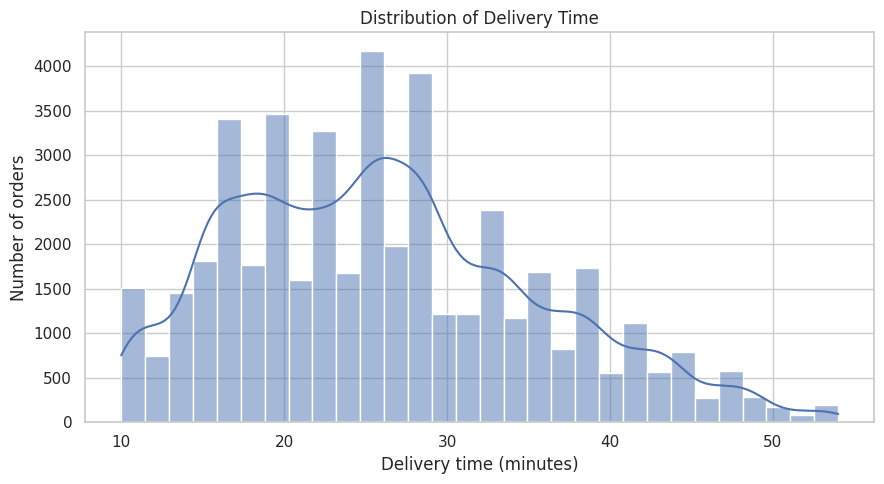

Delivery-time percentiles:


,minutes
0.00,10.0
0.05,13.0
0.25,19.0
0.50,26.0
0.75,32.0
0.90,40.0
0.95,44.0
0.99,49.0
1.00,54.0


In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(df[target].dropna(), bins=30, kde=True)
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery time (minutes)')
plt.ylabel('Number of orders')
plt.tight_layout()
plt.show()

print('Delivery-time percentiles:')
display(df[target].quantile([0, .05, .25, .50, .75, .90, .95, .99, 1]).to_frame('minutes'))

## 8. Inspect operating conditions

These summaries help us decide which business questions are answerable from the available data.

In [9]:
categorical_candidates = [
    'Weather_conditions', 'Road_traffic_density', 'Type_of_order',
    'Type_of_vehicle', 'Festival', 'City'
]

for column in categorical_candidates:
    if column in df.columns:
        print(f'\n{column} — value counts (including missing):')
        display(df[column].value_counts(dropna=False).head(15).to_frame('orders'))


Weather_conditions — value counts (including missing):


,orders
Weather_conditions,
Fog,7653
Stormy,7584
Cloudy,7533
Sandstorms,7494
Windy,7422
Sunny,7282
None,616



Road_traffic_density — value counts (including missing):


,orders
Road_traffic_density,
Low,15476
Jam,14139
Medium,10945
High,4423
None,601



Type_of_order — value counts (including missing):


,orders
Type_of_order,
Snack,11530
Meal,11456
Drinks,11321
Buffet,11277


... (2 outputs left out)


Festival — value counts (including missing):


,orders
Festival,
No,44460
Yes,896
None,228



City — value counts (including missing):


,orders
City,
Metropolitian,34087
Urban,10133
None,1200
Semi-Urban,164


## 9. Save the untouched source snapshot and audit report

These files are useful for reproducibility. In Colab, they are saved in the current session storage; download them to your project folder before closing the runtime.

In [10]:
raw_df.to_csv('fulfillment_pulse_source_snapshot.csv', index=False)
quality_report.to_csv('fulfillment_pulse_data_quality_report.csv')

print('Saved: fulfillment_pulse_source_snapshot.csv')
print('Saved: fulfillment_pulse_data_quality_report.csv')

Saved: fulfillment_pulse_source_snapshot.csv
Saved: fulfillment_pulse_data_quality_report.csv


## 10. Analyst notes — complete after running the notebook

Record the actual results from your run. Do not copy assumed numbers.

- Total rows and columns:
- Missing-value issues that need treatment:
- Duplicate rows / duplicate IDs:
- Invalid or suspicious coordinates:
- Delivery-time median and spread:
- Most useful operational dimensions:
- Data limitations to disclose:

**Next notebook:** Cleaning, feature engineering, exploratory analysis and operational KPI definitions.
